In [1]:
import numpy as np 
import pandas as pd


In [2]:
df=pd.read_csv('Customer_Behaviour_Hierarchical_Clean.csv')
cdf=df.copy()

In [3]:
cdf.head()

,CustomerID,MonthlyIncome,SpendingScore,PurchaseFrequency,OnlineHours
0,1,24000,18,2,4
1,2,26000,21,2,5
2,3,27500,24,3,5
3,4,29000,27,3,6
4,5,30500,30,3,6


In [4]:
cdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   CustomerID         30 non-null     int64
 1   MonthlyIncome      30 non-null     int64
 2   SpendingScore      30 non-null     int64
 3   PurchaseFrequency  30 non-null     int64
 4   OnlineHours        30 non-null     int64
dtypes: int64(5)
memory usage: 1.3 KB


In [5]:
cdf.isna().sum()

CustomerID           0
MonthlyIncome        0
SpendingScore        0
PurchaseFrequency    0
OnlineHours          0
dtype: int64

In [6]:
cdf.duplicated().sum()

np.int64(0)

In [8]:
cdf.shape

(30, 5)

In [7]:
cdf.corr(numeric_only=True)

,CustomerID,MonthlyIncome,SpendingScore,PurchaseFrequency,OnlineHours
CustomerID,1.000000,0.993919,0.999447,0.994318,0.993577
MonthlyIncome,0.993919,1.000000,0.991748,0.993660,0.996870
SpendingScore,0.999447,0.991748,1.000000,0.993306,0.992065
PurchaseFrequency,0.994318,0.993660,0.993306,1.000000,0.994504
OnlineHours,0.993577,0.996870,0.992065,0.994504,1.000000


In [10]:
X=cdf.drop(['CustomerID'],axis=1)

In [12]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()

x_scaled=scaler.fit_transform(X)


In [13]:
from sklearn.decomposition import PCA

pca=PCA(n_components=2,random_state=42)

x_pca=pca.fit_transform(x_scaled)


In [17]:
from sklearn.cluster import AgglomerativeClustering
hc=AgglomerativeClustering(
    n_clusters=2,
    linkage='ward'
)

labels=hc.fit_predict(x_scaled)

Text(0, 0.5, 'PCA2')

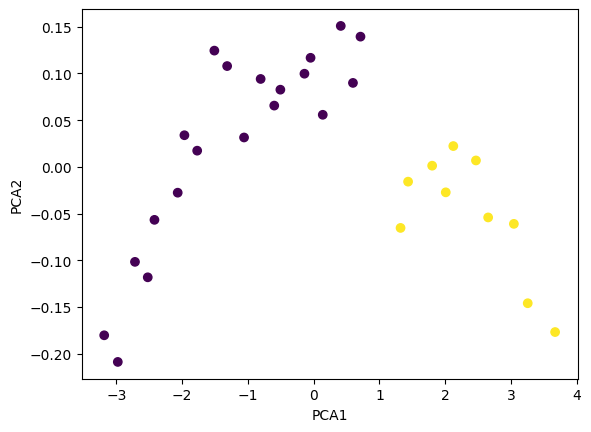

In [20]:
#Visualization Of Pca cluster
import matplotlib.pyplot as plt

plt.scatter(x_pca[:,0],
            x_pca[:,1],
            c=labels)

plt.xlabel('PCA1')
plt.ylabel('PCA2')


Text(0, 0.5, 'Distance')

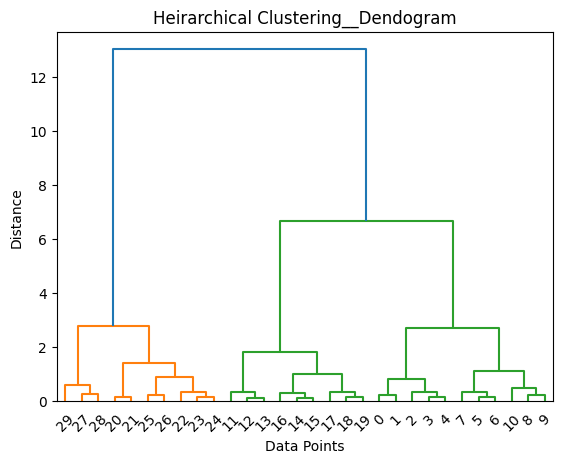

In [22]:
from scipy.cluster.hierarchy import dendrogram , linkage

linked=linkage(x_scaled,method='ward')

dendrogram(linked)
plt.title("Heirarchical Clustering__Dendogram")
plt.xlabel('Data Points')
plt.ylabel('Distance')

In [23]:
from sklearn.metrics import silhouette_score

silhouette_scores=[]

for k in range(2,11):
    hc=AgglomerativeClustering(
        n_clusters=k,
        linkage='ward',
    )
    labels=hc.fit_predict(x_scaled)
    score=silhouette_score(x_scaled,labels)
    silhouette_scores.append(score)

    print(score)

0.5856010790341437
0.5662344467893087
0.531657189949812
0.4978466804644447
0.47095306838046685
0.4548593847498186
0.45086297107496376
0.48851676039708586
0.5029636689932243


***Here the best shillout score is for cluster 2 so we will check for K=2 vlaue***

In [ ]:
hc_1=AgglomerativeClustering(n_clusters=2,linkage='ward')

cdf['Cluster_hc1']=hc_1.fit_predict(x_scaled)



***Cluster Profilling***

In [27]:
#K=2
cdf.groupby('Cluster_hc1')[X.columns].mean()

,MonthlyIncome,SpendingScore,PurchaseFrequency,OnlineHours
Cluster_hc1,,,,
0,41100.0,45.15,5.15,9.25
1,77700.0,85.40,10.70,19.00


***INSIGHTS***

Cluster 0: Middle class : person whoise average montly incom eis less has a less Spending score and do not purchases thing frequently also their online hours are less

Cluster 1: Rich : Person swhose average monthly income is more has a very high spending score because he purcased expensive items frequency and his online hours is also more he might be ordering the products from online ecommerce applications like amazon or flipcart 

Text(0, 0.5, 'PCA2')

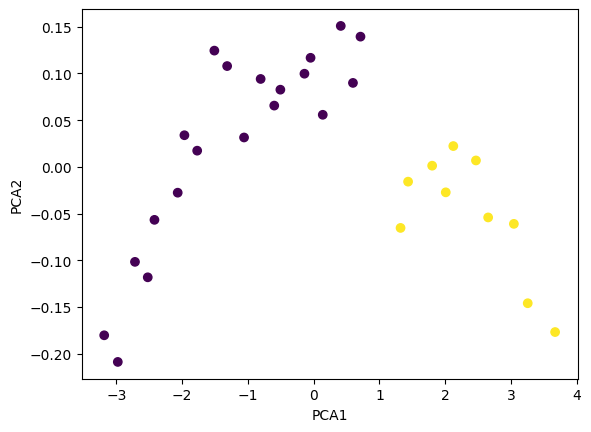

In [31]:
#Visualization Of Final Pca cluster
import matplotlib.pyplot as plt

plt.scatter(x_pca[:,0],
            x_pca[:,1],
            c=hc_1.fit_predict(x_scaled))

plt.xlabel('PCA1')
plt.ylabel('PCA2')
